# Master Document

Can be used to extract relative absorption from raw CSV files, then get divergence as well as flux.
Compacted code from [manual_divergence_fitting.ipynb](manual_divergence_fitting.ipynb) and [RelativeAbsFitterPlus_Old.ipynb](RelativeAbsFitterPlus_Old.ipynb).

**Author:** Isaac Cross  
**Lab:** Brian Odom Lab, Center for Fundamental Physics, Northwestern University  
**Date:** 04/08/2025  
**Contact:** crossisaac114@gmail.com

In [1]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
import math
import pyperclip
import os
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.stats import norm
import matplotlib.ticker as ticker

specify data to be used. And put file paths

In [ ]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_112825"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_112825"

In [2]:
def divergence_fitting_woffset(file_folder, file_name):
# ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)         
    p0_gaussian    = [0.05, 400, 100, 0.0]  # initial guess: [amplitude, center, sigma, offset]
    nozzleheight   = 0.150                # nozzle diameter (m)
    distancenozzle = 2.46                 # distance from nozzle to probe beam (m)
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # concatenate all 4 sides into single arrays for gaussian fit
    x_full = np.concatenate([df['height'].to_numpy()] * 4)
    y_full = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                            df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])

    # fit gaussian
    def gaussian(x, A, x0, sigma, offset):
        return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset

    popt, pvoc = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        absolute_sigma=False
    )

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # ── Plot ──────────────────────────────────────────────────────────────────────
    x_fit = np.linspace(0, 1000, 2000)
    y_fit = gaussian(x_fit, *popt)

    plt.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                fmt='x', markersize=3, linestyle='None', capsize=2, c="blue")
    plt.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue")
    plt.title("Relative Absorption Divergence Fit")
    plt.xlabel(r'$\Delta y$ [mm]')
    plt.ylabel("Relative Absorption [Arb. Units]")
    plt.show()

    # ── Extract fit parameters and widths ─────────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pvoc[2, 2])
    offset    = popt[3]
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
    print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")
    #print(f"Center (dx) = {dx}")

    # ── Reduced chi-squared ───────────────────────────────────────────────────────
    y_pred = gaussian(x_full, *popt)
    residuals = y_full - y_pred
    chi2 = np.sum((residuals / y_err) ** 2)
    ndof = len(y_full) - len(popt)          # degrees of freedom = N_points - N_params
    chi2_reduced = chi2 / ndof

    print(f"Reduced χ² = {chi2_reduced:.4f}  (χ² = {chi2:.2f}, dof = {ndof})")

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    print(f"Divergence half-angle (1/e width) = {divhalfangle_1e * 180 / math.pi:.3f} ± {divhalfangle_1e_err * 180 / math.pi:.3f} deg")

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    print(f"Divergence half-angle (FWHM)      = {divhalfangle_FWHM * 180 / math.pi:.3f} ± {divhalfangle_FWHM_err * 180 / math.pi:.3f} deg")

    return FWHM, FWHM_err, width_1e, width_1e_err, divhalfangle_1e, divhalfangle_1e_err, divhalfangle_FWHM, divhalfangle_FWHM_err, chi2_reduced



In [3]:
def divergence_fitting_nooffset(file_folder, file_name):
    # ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)         
    p0_gaussian    = [0.05, 400, 100]  # initial guess: [amplitude, center, sigma, offset]
    nozzleheight   = 0.150                # nozzle diameter (m)
    distancenozzle = 2.46                 # distance from nozzle to probe beam (m)
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # concatenate all 4 sides into single arrays for gaussian fit
    x_full = np.concatenate([df['height'].to_numpy()] * 4)
    y_full = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                            df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])

    # fit gaussian
    def gaussian(x, A, x0, sigma):
        return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))

    popt, pvoc = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        absolute_sigma=False
    )

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # ── Plot ──────────────────────────────────────────────────────────────────────
    x_fit = np.linspace(0, 1000, 2000)
    y_fit = gaussian(x_fit, *popt)

    plt.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                fmt='x', markersize=3, linestyle='None', capsize=2, c="blue")
    plt.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue")
    plt.title("Relative Absorption Divergence Fit")
    plt.xlabel(r'$\Delta y$ [mm]')
    plt.ylabel("Relative Absorption [Arb. Units]")
    plt.show()

    # ── Extract fit parameters and widths ─────────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pvoc[2, 2])
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
    print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")
    print(f"Center (dx) = {dx}")

    
    # ── Reduced chi-squared ───────────────────────────────────────────────────────
    y_pred = gaussian(x_full, *popt)
    residuals = y_full - y_pred
    chi2 = np.sum((residuals / y_err) ** 2)
    ndof = len(y_full) - len(popt)          # degrees of freedom = N_points - N_params
    chi2_reduced = chi2 / ndof

    print(f"Reduced χ² = {chi2_reduced:.4f}  (χ² = {chi2:.2f}, dof = {ndof})")

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    print(f"Divergence half-angle (1/e width) = {divhalfangle_1e * 180 / math.pi:.3f} ± {divhalfangle_1e_err * 180 / math.pi:.3f} deg")

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    print(f"Divergence half-angle (FWHM)      = {divhalfangle_FWHM * 180 / math.pi:.3f} ± {divhalfangle_FWHM_err * 180 / math.pi:.3f} deg")

    return FWHM, FWHM_err, width_1e, width_1e_err, divhalfangle_1e, divhalfangle_1e_err, divhalfangle_FWHM, divhalfangle_FWHM_err, chi2_reduced

# Fit Absorption Data

Modified version of  [manual_divergence_fitting.ipynb](manual_divergence_fitting.ipynb) . Runs over all CSV files of absorption data,
which each correspond to different probe beam positions. Will need to be modified based on setup;
suggest first using the manual version to get parameters right.

`sides` is the number of up and down ramps from the Toptica (or other laser) during the frequency sweep. Set the window
to save 4 total (2 up, 2 down). Start by separating each section, then fitting (currently with a 1st degree polynomial —
there are issues with this I hope to address soon, but I believe it may be the right thing to do; will update / if this
is still here email me for clarification) to remove the ramp. Finally, apply a Lorentzian fit (divergence low enough that
the lineshape is closer to Lorentzian (i.e. natural linewidth) than Gaussian; true fit would be a Voigt profile) to extract
relative height.

Keep in mind that the absorption data passed in here is heavily amplified, so it is not 1-1 with actual absorption, but instead gives the relative difference in absorption over a trial, as each trial has the same amplification (all this info should be in my senior thesis). Will update to include actual absorption later.

Finally, outputs a CSV containing relative absorption for each side with error, for each probe beam position in the data folder.

In [ ]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_112825"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_112825"

# ── CONFIGURATION 
csv_folder   = absorption_data_folder                          # CSV input folder
plots_folder = os.path.join(results_folder, "fit_plots")      # fit plot output folder
output_file  = os.path.join(results_folder, "divergence_results.csv")  # results CSV
save_plots   = True                                            # save fit plots
sides        = ["1", "2", "3", "4"]                           # sides to fit
degree = 2 # i do not like this, but degree = 1 gets weird/inconsistent results
# ──────────────────────────────────────────────────────────────────────────────

# fit equation
def lorentz(x, G):
    return 1.0 / (1.0 + (x / (G / 2.0))**2)

def model_function(x, G, scale, dx, offset):
    return scale * lorentz(x - dx, G) + offset

# auto-detect heights from all CSV files in csv_folder
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith(".csv")])
heights   = [os.path.splitext(f)[0] for f in csv_files]

# create output directories if they don't exist
if save_plots:
    os.makedirs(plots_folder, exist_ok=True)
os.makedirs(os.path.dirname(output_file) or ".", exist_ok=True)

print(f"Found {len(heights)} CSV files: {heights}")

results = []  # list of dicts, one per height

for height in heights:
    filepath = os.path.join(csv_folder, f"{height}.csv")
    row = {"height": height}

    for side in sides:
        try:
            # ── Cell 4 logic ────────────────────────────────────────────────────
            data = pd.read_csv(filepath)

            t_min, t_max = -np.inf, np.inf
            if side == "n":
                t_min, t_max = -np.inf, np.inf
            elif side == "1":
                t_min, t_max = -0.003, -0.00105
            elif side == "2":
                t_min, t_max = -0.0009, 0.001
            elif side == "3":
                t_min, t_max = 0.0011, 0.003
            elif side == "4":
                t_min, t_max = 0.0031, 0.005

            data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
            t   = data_filtered['Time(s)']
            CH2 = data_filtered["CH2(V)"]

            # ── Cell 5 logic ────────────────────────────────────────────────────
            #filter data to not include the peaks 
            if side == "1":
                t_remove_min, t_remove_max = -0.0023, -0.00145
            elif side =="2":
                t_remove_min, t_remove_max = -0.0005, 0.00025
            elif side =="3":
                t_remove_min, t_remove_max = 0.00175, 0.00275
            elif side == "4":
                t_remove_min, t_remove_max = 0.0035, 0.0045
    
            data_subtrac_ramp = data_filtered[
                (data_filtered['Time(s)'] < t_remove_min) |
                (data_filtered['Time(s)'] > t_remove_max)
            ]
            t_ramp   = data_subtrac_ramp['Time(s)']
            CH2_ramp = data_subtrac_ramp["CH2(V)"]

            coeffs = np.polyfit(t_ramp, CH2_ramp, deg=degree)
            ramp   = np.polyval(coeffs, t)

            resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
            dof_r   = len(t_ramp) - 3
            sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

            Rb_spectrum = -(CH2 - ramp)

            # ── Cell 6 logic ────────────────────────────────────────────────────

            if side == "1":
                dx_guess = -0.00185
            elif side == "2":
                dx_guess = -0.0002
            elif side == "3":
                dx_guess = 0.00225
            elif side == "4":
                dx_guess = 0.0039

            H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
            p0 = [2.0e-4, H_guess, dx_guess, 0.0]
            lb = [1e-12, 0.0, -np.inf, -np.inf]
            ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

            popt, pcov = curve_fit(
                model_function, t, Rb_spectrum,
                p0=p0, sigma=sigma_y, absolute_sigma=True,
                bounds=(lb, ub), method="trf", maxfev=1000
            )

            G, scale, dx, offset = popt
            eG, escale, edx, eoffset = np.sqrt(np.diag(pcov))

            # replace NaN with 0 if fit converged but parameters are invalid
            scale  = 0 if np.isnan(scale)  else scale
            escale = 0 if np.isnan(escale) else escale

            # save fit plot
            if save_plots:
                y_fit = model_function(t, *popt)
                fig, ax = plt.subplots()
                ax.plot(t, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
                ax.plot(t, y_fit, label="fit", color="blue")
                ax.set_xlabel("Relative Laser Detuning, relative F=3-->4 (A.U.)")
                ax.set_ylabel("Relative Voltage Changes (A.U.)")
                ax.set_title(filepath)
                ax.legend(loc='best')
                fig.savefig(os.path.join(plots_folder, f"{height}_side{side}_fit.png"), dpi=100)
                plt.close(fig)

            row[f"Scale{side}"]  =  0 if np.isnan(scale)  else abs(model_function(dx, *popt))  # this was the issue!!! oh thank god.... okay, wellll make this better formated, this was test. 
            row[f"eScale{side}"] = escale
            #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")

        except Exception as e:
            print(f"FAILED: {filepath} side={side} → {e}")
            row[f"Scale{side}"]  = 0
            row[f"eScale{side}"] = 0

    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv(output_file, index=False)
print(f"\nSaved → {output_file}")
df_out

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x000001E468F1EFD0>>
Traceback (most recent call last):
  File "C:\Users\ikcco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\ipykernel\ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


NameError: name 'absorption_data_folder' is not defined

# Divergence Fit/Calc

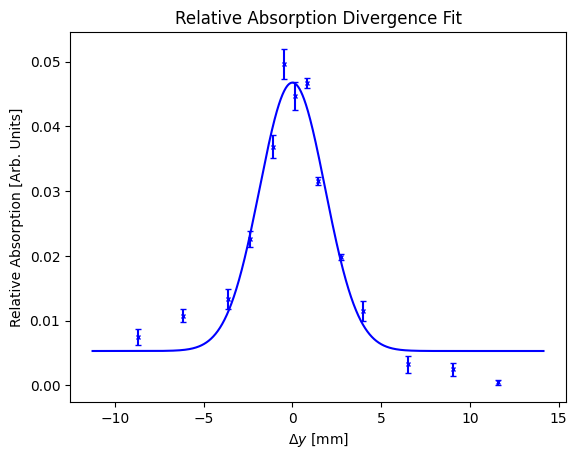

FWHM = 171.04 ± 8.49
1/e width = 205.44 ± 10.19
Reduced χ² = 25.9404  (χ² = 259.40, dof = 10)
Divergence half-angle (1/e width) = 0.646 ± 0.119 deg
Divergence half-angle (FWHM)      = 0.245 ± 0.099 deg


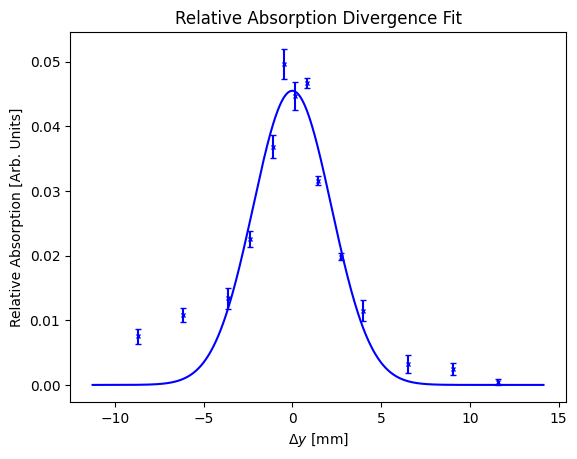

FWHM = 204.24 ± 9.45
1/e width = 245.32 ± 11.35
Center (dx) = 442.8972658413669
Reduced χ² = 23.3411  (χ² = 256.75, dof = 11)
Divergence half-angle (1/e width) = 1.110 ± 0.132 deg
Divergence half-angle (FWHM)      = 0.632 ± 0.110 deg


In [20]:
# folder where all results (CSV + plots) will be saved
results_folder = "results/results_112825"

x = divergence_fitting_woffset(results_folder, "divergence_results.csv")
x = divergence_fitting_nooffset(results_folder, "divergence_results.csv")

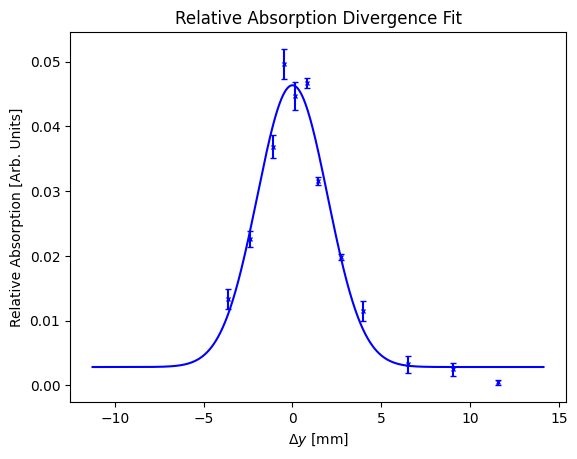

FWHM = 183.68 ± 8.47
1/e width = 220.62 ± 10.18
Reduced χ² = 15.6042  (χ² = 124.83, dof = 8)
Divergence half-angle (1/e width) = 0.822 ± 0.118 deg
Divergence half-angle (FWHM)      = 0.392 ± 0.099 deg


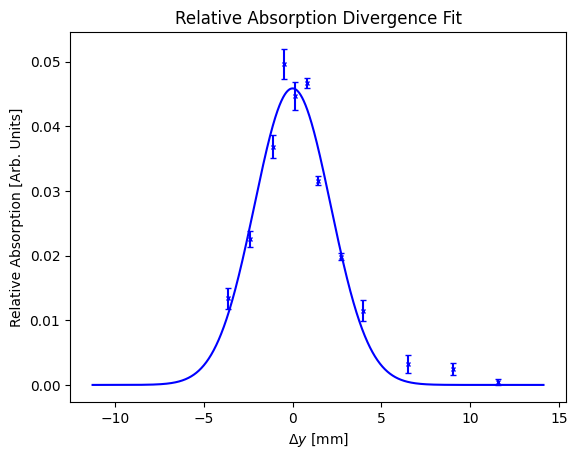

FWHM = 198.84 ± 7.28
1/e width = 238.83 ± 8.74
Center (dx) = 443.5292614066597
Reduced χ² = 13.4058  (χ² = 120.65, dof = 9)
Divergence half-angle (1/e width) = 1.034 ± 0.102 deg
Divergence half-angle (FWHM)      = 0.569 ± 0.085 deg


In [22]:
x = divergence_fitting_woffset(results_folder, "divergence_results_test2.csv")
x = divergence_fitting_nooffset(results_folder, "divergence_results_test2.csv")

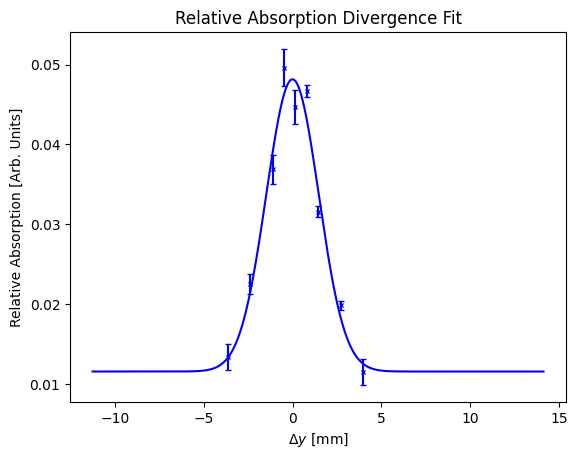

FWHM = 136.76 ± 11.28
1/e width = 164.27 ± 13.55
Reduced χ² = 11.4404  (χ² = 57.20, dof = 5)
Divergence half-angle (1/e width) = 0.166 ± 0.158 deg
Divergence half-angle (FWHM)      = -0.154 ± 0.131 deg


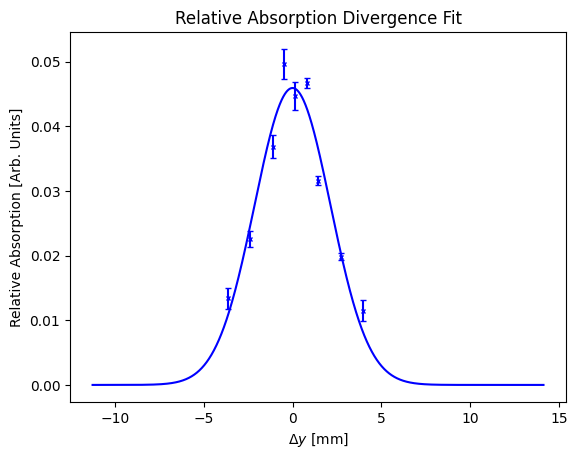

FWHM = 197.98 ± 7.94
1/e width = 237.80 ± 9.53
Center (dx) = 443.43381549169715
Reduced χ² = 17.8078  (χ² = 106.85, dof = 6)
Divergence half-angle (1/e width) = 1.022 ± 0.111 deg
Divergence half-angle (FWHM)      = 0.559 ± 0.092 deg


In [21]:
x = divergence_fitting_woffset(results_folder, "divergence_results_test.csv")
x = divergence_fitting_nooffset(results_folder, "divergence_results_test.csv")

In [25]:
def divergence_fitting_woffset_ai(file_folder, file_name):
# ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)         
    p0_gaussian    = [0.05, 400, 100, 0.0]  # initial guess: [amplitude, center, sigma, offset]
    nozzleheight   = 0.150                # nozzle diameter (m)
    distancenozzle = 2.46                 # distance from nozzle to probe beam (m)
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # concatenate all 4 sides into single arrays for gaussian fit
    x_full = np.concatenate([df['height'].to_numpy()] * 4)
    y_full = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                            df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])

    # fit gaussian
    def gaussian(x, A, x0, sigma, offset):
        return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset

    popt, pvoc = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        absolute_sigma=False
    )

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # ── Reduced chi-squared ───────────────────────────────────────────────────
    y_pred = gaussian(x_full, *popt)
    residuals = y_full - y_pred

    error_floor = 0.1 * np.max(y_full)
    y_err_floored = np.maximum(y_err, error_floor)

    chi2 = np.sum((residuals / y_err_floored) ** 2)
    ndof = len(y_full) - len(popt)
    chi2_reduced = chi2 / ndof

    print(f"Reduced χ² = {chi2_reduced:.4f}  (χ² = {chi2:.2f}, dof = {ndof})")

    # ── Plot ──────────────────────────────────────────────────────────────────
    x_fit = np.linspace(0, 1000, 2000)
    y_fit = gaussian(x_fit, *popt)

    plt.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                fmt='x', markersize=3, linestyle='None', capsize=2, c="blue")
    plt.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue")
    plt.title("Relative Absorption Divergence Fit")
    plt.xlabel(r'$\Delta y$ [mm]')
    plt.ylabel("Relative Absorption [Arb. Units]")
    plt.show()

    # ── Extract fit parameters and widths ─────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pvoc[2, 2])
    offset    = popt[3]
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
    print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    print(f"Divergence half-angle (1/e width) = {divhalfangle_1e * 180 / math.pi:.3f} ± {divhalfangle_1e_err * 180 / math.pi:.3f} deg")

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    print(f"Divergence half-angle (FWHM)      = {divhalfangle_FWHM * 180 / math.pi:.3f} ± {divhalfangle_FWHM_err * 180 / math.pi:.3f} deg")

    return FWHM, FWHM_err, width_1e, width_1e_err, divhalfangle_1e, divhalfangle_1e_err, divhalfangle_FWHM, divhalfangle_FWHM_err

def divergence_fitting_nooffset_ai(file_folder, file_name):
    # ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)         
    p0_gaussian    = [0.05, 400, 100]  # initial guess: [amplitude, center, sigma]
    nozzleheight   = 0.150                # nozzle diameter (m)
    distancenozzle = 2.46                 # distance from nozzle to probe beam (m)
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # concatenate all 4 sides into single arrays for gaussian fit
    x_full = np.concatenate([df['height'].to_numpy()] * 4)
    y_full = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                            df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])

    # fit gaussian
    def gaussian(x, A, x0, sigma):
        return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))

    popt, pvoc = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        absolute_sigma=False
    )

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # ── Reduced chi-squared ───────────────────────────────────────────────────
    y_pred = gaussian(x_full, *popt)
    residuals = y_full - y_pred

    error_floor = 0.1 * np.max(y_full)
    y_err_floored = np.maximum(y_err, error_floor)

    chi2 = np.sum((residuals / y_err_floored) ** 2)
    ndof = len(y_full) - len(popt)
    chi2_reduced = chi2 / ndof

    print(f"Reduced χ² = {chi2_reduced:.4f}  (χ² = {chi2:.2f}, dof = {ndof})")

    # ── Plot ──────────────────────────────────────────────────────────────────
    x_fit = np.linspace(0, 1000, 2000)
    y_fit = gaussian(x_fit, *popt)

    plt.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                fmt='x', markersize=3, linestyle='None', capsize=2, c="blue")
    plt.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue")
    plt.title("Relative Absorption Divergence Fit")
    plt.xlabel(r'$\Delta y$ [mm]')
    plt.ylabel("Relative Absorption [Arb. Units]")
    plt.show()

    # ── Extract fit parameters and widths ─────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pvoc[2, 2])
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
    print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")
    print(f"Center (dx) = {dx}")

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    print(f"Divergence half-angle (1/e width) = {divhalfangle_1e * 180 / math.pi:.3f} ± {divhalfangle_1e_err * 180 / math.pi:.3f} deg")

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    print(f"Divergence half-angle (FWHM)      = {divhalfangle_FWHM * 180 / math.pi:.3f} ± {divhalfangle_FWHM_err * 180 / math.pi:.3f} deg")

    return FWHM, FWHM_err, width_1e, width_1e_err, divhalfangle_1e, divhalfangle_1e_err, divhalfangle_FWHM, divhalfangle_FWHM_err, chi2_reduced

Reduced χ² = 0.9938  (χ² = 10.93, dof = 11)


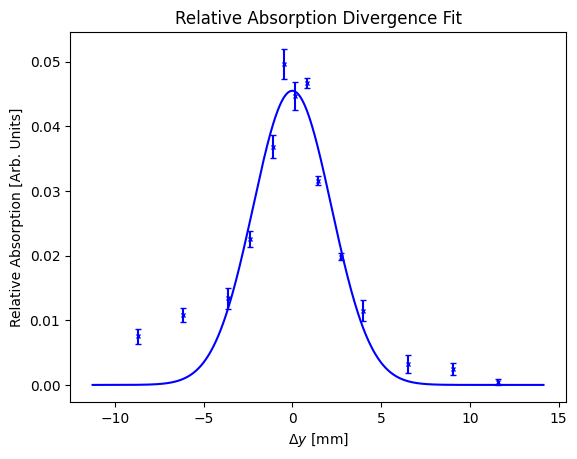

FWHM = 204.24 ± 9.45
1/e width = 245.32 ± 11.35
Center (dx) = 442.8972658413669
Divergence half-angle (1/e width) = 1.110 ± 0.132 deg
Divergence half-angle (FWHM)      = 0.632 ± 0.110 deg


In [28]:
x = divergence_fitting_nooffset_ai(results_folder, "divergence_results.csv")

Reduced χ² = 0.5132  (χ² = 4.62, dof = 9)


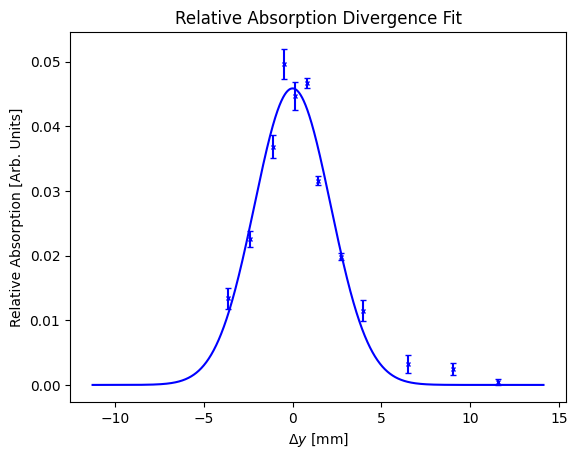

FWHM = 198.84 ± 7.28
1/e width = 238.83 ± 8.74
Center (dx) = 443.5292614066597
Divergence half-angle (1/e width) = 1.034 ± 0.102 deg
Divergence half-angle (FWHM)      = 0.569 ± 0.085 deg


In [ ]:
x = divergence_fitting_nooffset_ai(results_folder, "divergence_results_test2.csv")

Reduced χ² = 0.6755  (χ² = 4.05, dof = 6)


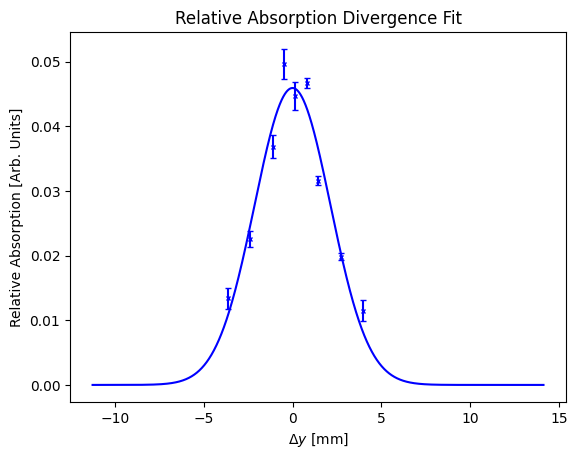

FWHM = 197.98 ± 7.94
1/e width = 237.80 ± 9.53
Center (dx) = 443.43381549169715
Divergence half-angle (1/e width) = 1.022 ± 0.111 deg
Divergence half-angle (FWHM)      = 0.559 ± 0.092 deg


In [29]:
x = divergence_fitting_nooffset_ai(results_folder, "divergence_results_test.csv")

Create a pretty lil plot :)

I might want to change how this is plotted, as in where is zero and maybe make the max of fit be 1? Ask brian/daniel

Text(-1.4441197379938784, 0.38, '1/e width')

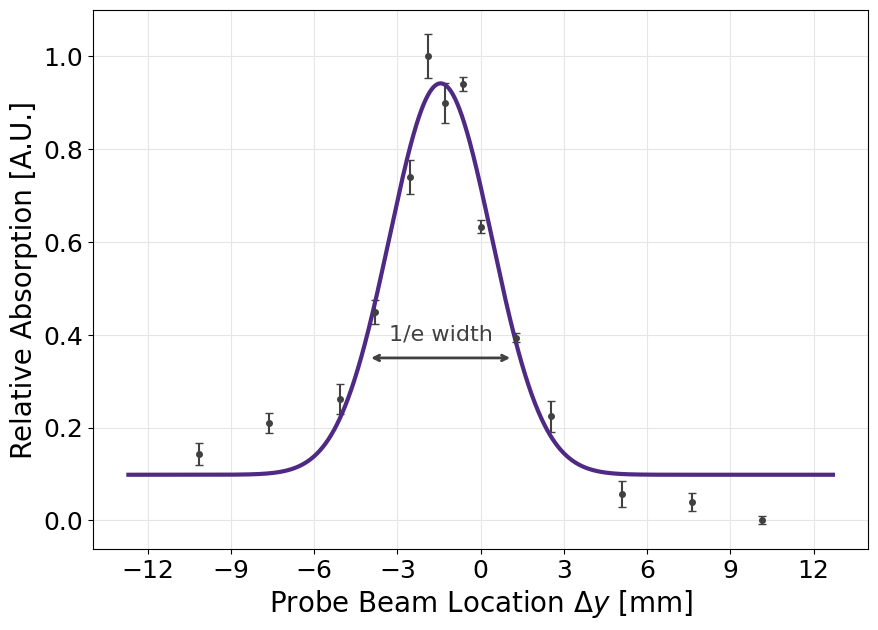

In [9]:
plt.figure(figsize=(10, 7))

plt.errorbar((x_full - 500) / (39.3701 * 1),
              (y_full - np.min(y_full))/(np.max(y_full) - np.min(y_full)), 
             yerr=y_err/(y_full.max()-y_full.min()),
             fmt='o',markersize=4,linestyle='None',capsize=3,c= "#414141")
plt.plot((x_fit - 500) / (39.3701 * 1), 
         (y_fit - np.min(y_full))/(np.max(y_full) - np.min(y_full)),
         c="#4E2A84", lw = "3")

plt.grid(True, color='0.9', linewidth=0.8)
#plt.title("Relative Absorption Divergence Fit",fontsize = "28")
plt.xticks(np.arange(-12, 12.1, 3),fontsize = "18")
plt.yticks(fontsize = "18")
plt.xlabel(r'Probe Beam Location $\Delta y$ [mm]',fontsize = "20")
plt.ylabel("Relative Absorption [A.U.]",fontsize = "20")

# --- FWHM double-arrow on the normalized plot ---
# sigma  = popt[2]
# FWHM   = 2*np.sqrt(2*np.log(2))*sigma

# x0_plot   = (popt[1] - 500)/39.3701
# half_span = (FWHM/2)/39.3701
# xL, xR    = x0_plot - half_span, x0_plot + half_span

# ax = plt.gca()
# ax.annotate('', xy=(xL, 0.5), xytext=(xR, 0.5),
#             arrowprops=dict(arrowstyle='<->', lw=2, color='#4E2A84'))
# ax.text(x0_plot, 0.4, 'FWHM', ha='center', va='bottom', fontsize=16, color='#4E2A84')

# --- 1/e width double-arrow on the normalized plot ---


x0_plot   = (popt[1] - 500)/39.3701
half_span = (width_1e/2)/39.3701
xL, xR    = x0_plot - half_span, x0_plot + half_span

ax = plt.gca()
ax.annotate('', xy=(xL, 0.35), xytext=(xR, 0.35),
            arrowprops=dict(arrowstyle='<->', lw=2, color='#414141'))
ax.text(x0_plot, 0.38, '1/e width', ha='center', va='bottom',
        fontsize=16, color='#414141')

# Flux!

Time to convert A.U. to atoms/s

In [ ]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_101225"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_101225/Near/flux_data"


# # folder containing the scope trace CSVs, one per beam height/position
# absorption_data_folder = "absorption_data/data_112825/flux_data"

# # folder where all results (CSV + plots) will be saved
# results_folder = "results/results_112825/flux_data"

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
csv_folder   = absorption_data_folder                          # CSV input folder
plots_folder = os.path.join(results_folder, "fit_plots")      # fit plot output folder
output_file  = os.path.join(results_folder, "flux_results.csv")  # results CSV
save_plots   = True                                            # save fit plots
sides        = ["1", "2", "3", "4"]                           # sides to fit
degree = 2 # i do not like this, but degree = 1 gets weird/inconsistent results
# ──────────────────────────────────────────────────────────────────────────────

# fit equation
def lorentz(x, G):
    return 1.0 / (1.0 + (x / (G / 2.0))**2)

def model_function(x, G, scale, dx, offset):
    return scale * lorentz(x - dx, G) + offset

# auto-detect heights from all CSV files in csv_folder
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith(".csv")])
heights   = [os.path.splitext(f)[0] for f in csv_files]

# create output directories if they don't exist
if save_plots:
    os.makedirs(plots_folder, exist_ok=True)
os.makedirs(os.path.dirname(output_file) or ".", exist_ok=True)

print(f"Found {len(heights)} CSV files: {heights}")

results = []  # list of dicts, one per height

for height in heights:
    filepath = os.path.join(csv_folder, f"{height}.csv")
    row = {"height": height}

    for side in sides:
        # ── Cell 4 logic ────────────────────────────────────────────────────
        data = pd.read_csv(filepath)

        t_min, t_max = -np.inf, np.inf
        if side == "n":
            t_min, t_max = -np.inf, np.inf
        elif side == "1":
            t_min, t_max = -0.003, -0.00105
        elif side == "2":
            t_min, t_max = -0.0009, 0.001
        elif side == "3":
            t_min, t_max = 0.0011, 0.003
        elif side == "4":
            t_min, t_max = 0.0031, 0.005

        data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
        t   = data_filtered['Time(s)']
        CH2 = data_filtered["CH2(V)"]

        # ── Cell 5 logic ────────────────────────────────────────────────────
        #filter data to not include the peaks 
        if side == "1":
            t_remove_min, t_remove_max = -0.0023, -0.00145
        elif side =="2":
            t_remove_min, t_remove_max = -0.0005, 0.00025
        elif side =="3":
            t_remove_min, t_remove_max = 0.00175, 0.00275
        elif side == "4":
            t_remove_min, t_remove_max = 0.0035, 0.0045

        data_subtrac_ramp = data_filtered[
            (data_filtered['Time(s)'] < t_remove_min) |
            (data_filtered['Time(s)'] > t_remove_max)
        ]
        t_ramp   = data_subtrac_ramp['Time(s)']
        CH2_ramp = data_subtrac_ramp["CH2(V)"]

        coeffs = np.polyfit(t_ramp, CH2_ramp, deg=degree)
        ramp   = np.polyval(coeffs, t)

        resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
        dof_r   = len(t_ramp) - 3
        sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

        Rb_spectrum = -(CH2 - ramp)


        # Convert from voltage to percent absorption (plz plz plz check this math)
        # A%(t) = 100 * (1 - V/V0), with V0 = ramp #make sure is true/cite or smth
        V = np.asarray(CH2, dtype=float)
        V0 = np.asarray(ramp, dtype=float)

        valid = V0 > 0
        A_pct = np.full_like(V0, np.nan, dtype=float)
        A_pct[valid] = 100.0 * (1.0 - V[valid] / V0[valid])
        # change how this is writen to smtjh that makes sense 

        # ── Cell 6 logic ────────────────────────────────────────────────────
        Rb_spectrum = A_pct

        if side == "1":
            dx_guess = -0.00185
        elif side == "2":
            dx_guess = -0.0002
        elif side == "3":
            dx_guess = 0.00225
        elif side == "4":
            dx_guess = 0.0039

        H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
        p0 = [2.0e-4, H_guess, dx_guess, 0.0]
        lb = [1e-12, 0.0, -np.inf, -np.inf]
        ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

        popt, pcov = curve_fit(
            model_function, t, Rb_spectrum,
            p0=p0, sigma=sigma_y, absolute_sigma=True,
            bounds=(lb, ub), method="trf", maxfev=1000
        )

        G, scale, dx, offset = popt
        eG, escale, edx, eoffset = np.sqrt(np.diag(pcov))


        # save fit plot
        if save_plots:
            y_fit = model_function(t, *popt)
            t_ms = t * 1000

            x_pad = 0.05 * (t_ms.max() - t_ms.min())
            y_all = np.concatenate([np.asarray(Rb_spectrum), y_fit])
            y_pad = 0.15 * (np.nanmax(y_all) - np.nanmin(y_all))

            fig, ax = plt.subplots()
            ax.plot(t_ms, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
            ax.plot(t_ms, y_fit, label="fit", color="blue")
            ax.set_xlim(t_ms.min() - x_pad, t_ms.max() + x_pad)
            ax.set_ylim(np.nanmin(y_all) - y_pad, np.nanmax(y_all) + y_pad)
            ax.set_xlabel("Laser Scan Time (ms)")
            ax.set_ylabel("Absorption (%)")
            ax.set_title(filepath)
            ax.legend(loc='best')
            fig.savefig(os.path.join(plots_folder, f"{height}_side{side}_fit.png"), dpi=100, bbox_inches='tight')
            plt.close(fig)
            
        row[f"Scale{side}"]  =  scale
        row[f"eScale{side}"] = escale
        #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")


    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv(output_file, index=False)
print(f"\nSaved → {output_file}")
df_out

Found 1 CSV files: ['full2converted']


KeyboardInterrupt: 

In [5]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_101225"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_101225/Far/flux_data"

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
csv_folder   = absorption_data_folder                          # CSV input folder
plots_folder = os.path.join(results_folder, "fit_plots")      # fit plot output folder
output_file  = os.path.join(results_folder, "flux_results.csv")  # results CSV
save_plots   = True                                            # save fit plots
sides        = ["1", "2", "3", "4"]                           # sides to fit
degree = 2 # i do not like this, but degree = 1 gets weird/inconsistent results
# ──────────────────────────────────────────────────────────────────────────────

# fit equation
def lorentz(x, G):
    return 1.0 / (1.0 + (x / (G / 2.0))**2)

def model_function(x, G, scale, dx, offset):
    return scale * lorentz(x - dx, G) + offset

# auto-detect heights from all CSV files in csv_folder
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith(".csv")])
heights   = [os.path.splitext(f)[0] for f in csv_files]

# create output directories if they don't exist
if save_plots:
    os.makedirs(plots_folder, exist_ok=True)
os.makedirs(os.path.dirname(output_file) or ".", exist_ok=True)

print(f"Found {len(heights)} CSV files: {heights}")

results = []  # list of dicts, one per height

for height in heights:
    filepath = os.path.join(csv_folder, f"{height}.csv")
    row = {"height": height}

    for side in sides:
        # ── Cell 4 logic ────────────────────────────────────────────────────
        data = pd.read_csv(filepath)

        t_min, t_max = -np.inf, np.inf
        if side == "n":
            t_min, t_max = -np.inf, np.inf
        elif side == "1":
            t_min, t_max = -0.003, -0.00105
        elif side == "2":
            t_min, t_max = -0.0009, 0.001
        elif side == "3":
            t_min, t_max = 0.0011, 0.003
        elif side == "4":
            t_min, t_max = 0.0031, 0.005

        data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
        t   = data_filtered['Time(s)']
        CH2 = data_filtered["CH2(V)"]

        # ── Cell 5 logic ────────────────────────────────────────────────────
        #filter data to not include the peaks 
        if side == "1":
            t_remove_min, t_remove_max = -0.0023, -0.00145
        elif side =="2":
            t_remove_min, t_remove_max = -0.0005, 0.00025
        elif side =="3":
            t_remove_min, t_remove_max = 0.00175, 0.00275
        elif side == "4":
            t_remove_min, t_remove_max = 0.0035, 0.0045

        data_subtrac_ramp = data_filtered[
            (data_filtered['Time(s)'] < t_remove_min) |
            (data_filtered['Time(s)'] > t_remove_max)
        ]
        t_ramp   = data_subtrac_ramp['Time(s)']
        CH2_ramp = data_subtrac_ramp["CH2(V)"]

        coeffs = np.polyfit(t_ramp, CH2_ramp, deg=degree)
        ramp   = np.polyval(coeffs, t)

        resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
        dof_r   = len(t_ramp) - 3
        sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

        Rb_spectrum = -(CH2 - ramp)


        # Convert from voltage to percent absorption (plz plz plz check this math)
        # A%(t) = 100 * (1 - V/V0), with V0 = ramp #make sure is true/cite or smth
        V = np.asarray(CH2, dtype=float)
        V0 = np.asarray(ramp, dtype=float)

        valid = V0 > 0
        A_pct = np.full_like(V0, np.nan, dtype=float)
        A_pct[valid] = 100.0 * (1.0 - V[valid] / V0[valid])
        # change how this is writen to smtjh that makes sense 

        # ── Cell 6 logic ────────────────────────────────────────────────────
        Rb_spectrum = A_pct

        if side == "1":
            dx_guess = -0.0022
        elif side == "2":
            dx_guess = 0.0001
        elif side == "3":
            dx_guess = 0.0019
        elif side == "4":
            dx_guess = 0.0041

        H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
        p0 = [2.0e-4, H_guess, dx_guess, 0.0]
        lb = [1e-12, 0.0, -np.inf, -np.inf]
        ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

        popt, pcov = curve_fit(
            model_function, t, Rb_spectrum,
            p0=p0, sigma=sigma_y, absolute_sigma=True,
            bounds=(lb, ub), method="trf", maxfev=1000
        )

        G, scale, dx, offset = popt
        eG, escale, edx, eoffset = np.sqrt(np.diag(pcov))


        # save fit plot
        if save_plots:
            y_fit = model_function(t, *popt)
            t_ms = t * 1000

            x_pad = 0.05 * (t_ms.max() - t_ms.min())
            y_all = np.concatenate([np.asarray(Rb_spectrum), y_fit])
            y_pad = 0.15 * (np.nanmax(y_all) - np.nanmin(y_all))

            fig, ax = plt.subplots()
            ax.plot(t_ms, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
            ax.plot(t_ms, y_fit, label="fit", color="blue")
            ax.set_xlim(t_ms.min() - x_pad, t_ms.max() + x_pad)
            ax.set_ylim(np.nanmin(y_all) - y_pad, np.nanmax(y_all) + y_pad)
            ax.set_xlabel("Laser Scan Time (ms)")
            ax.set_ylabel("Absorption (%)")
            ax.set_title(filepath)
            ax.legend(loc='best')
            fig.savefig(os.path.join(plots_folder, f"{height}_side{side}_fit.png"), dpi=100, bbox_inches='tight')
            plt.close(fig)
            
        row[f"Scale{side}"]  =  scale
        row[f"eScale{side}"] = escale
        #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")


    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv(output_file, index=False)
print(f"\nSaved → {output_file}")
df_out

Found 1 CSV files: ['full2converted']

Saved → results/results_101225/Far/flux_data\flux_results.csv


,height,Scale1,eScale1,Scale2,eScale2,Scale3,eScale3,Scale4,eScale4
0,full2converted,0.021375,2.426931e-07,0.033383,2.766014e-07,0.026467,2.198351e-07,0.027573,2.219709e-07


In [2]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_112825/flux_data"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_112825/flux_data"

output_file  = os.path.join(results_folder, "flux_results.csv") 
df = pd.read_csv(output_file)

# get absorption percents 
absorptions = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                         df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])
abs_mean = absorptions.mean()

#constants (Steck)
Isat = 3.895 #mW/cm^2
sigma_eff = 1.248*10**(-9) #cm^2 #isotropic polarization, but I think I had pi? Look into for future...
fF3 = 7/12 # i have no idea, "Boltzman weigthing with hyperfine degeneracy... " order of mag should still be right
PRb85 = 0.7217


T0 = 1 - abs_mean/100 #get transmission at resoanance/peak
OD0 = -math.log(T0) #optical density

nRb85 = OD0/(sigma_eff*fF3) #num Rb85F=3->F'=4 #cm^-2

nRb = nRb85/PRb85

interaction_len = 238/1000*2.54 #cm, 1/e width

number_density_R_cm = nRb/interaction_len

number_density_R_m = number_density_R_cm*1000000

print(f"Rb density cm^-3: {number_density_R_cm:.2e}")

print(f"Rb density m^-3: {number_density_R_m:.2e}")

Rb density cm^-3: 2.11e+06
Rb density m^-3: 2.11e+12


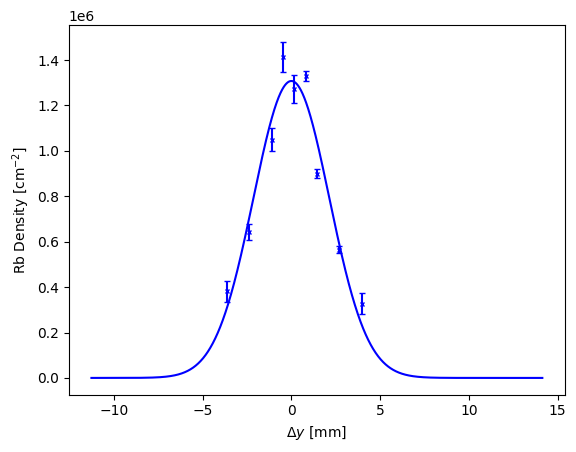

N_cross_section: 7.001e+05 cm^-1


In [5]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_112825"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_112825"

# ── INPUTS ────────────────────────────────────────────────────────────────────
filepath3      = os.path.join(results_folder, "divergence_results_test.csv")         
p0_gaussian    = [0.05, 400, 100]  # initial guess: [amplitude, center, sigma, offset]
nozzleheight   = 0.150                # nozzle diameter (m)
distancenozzle = 2.46                 # distance from nozzle to probe beam (m)
unit_conv      = 39.3701              # unit conversion factor applied to x-axis
# ──────────────────────────────────────────────────────────────────────────────

# load results CSV
df = pd.read_csv(filepath3)

# concatenate all 4 sides into single arrays for gaussian fit
x_full = np.concatenate([df['height'].to_numpy()] * 4)
y_full = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),
                         df['Scale3'].to_numpy(), df['Scale4'].to_numpy()])

# fit gaussian
def gaussian(x, A, x0, sigma):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))

popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0=p0_gaussian,
    absolute_sigma=False
)

# compute mean and std error across sides for plotting
A, x0, sigma = popt
x_full = df['height']
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

rescale = nRb/y_full[4]

# ── Plot ──────────────────────────────────────────────────────────────────────
x_fit = np.linspace(0, 1000, 2000)
y_fit = rescale*gaussian(x_fit, *popt)

plt.errorbar((x_full - x0) / unit_conv, rescale*y_full, yerr=rescale*y_err,
             fmt='x', markersize=3, linestyle='None', capsize=2, c="blue")
plt.plot((x_fit - x0) / unit_conv, y_fit, c="blue")
#plt.title("Relative Absorption Divergence Fit")
plt.xlabel(r'$\Delta y$ [mm]')
plt.ylabel(r'Rb Density [cm$^{-2}$]') #fix name of....
plt.show()

x_integrate = np.linspace(0,2.54,2000) #cm size is same and intiail x_fit is this but in thou an in
N_cross_section = np.trapezoid(y_fit,x_integrate) #cm^-1, cross section across full Rb beam, from ~0.5 mm probe beam

print(f"N_cross_section: {N_cross_section:.3e} cm^-1")

In [6]:
#now go from cross section number of Rb to flux!!! :)

#first need to find v rb
#const
T_K       = 273+230          # temperature of oven, K
m_rb      = 85.4678 * 1.66053906660e-27  # Rb mass, kg
kB        = 1.380649e-23

delta_z = 0.55*10**(-3) #size beam/cross section thickness, m

# VRMS
v_rms = math.sqrt(2*kB*T_K/m_rb)*100

#get flux.
Rb_flux_total = N_cross_section*v_rms

print(f"{Rb_flux_total:.2e}")

2.19e+10


For 101225

In [22]:
# folder containing the scope trace CSVs, one per beam height/position
absorption_data_folder = "absorption_data/data_101225/Near - Copy"

# folder where all results (CSV + plots) will be saved
results_folder = "results/results_101225/Near"

# ── CONFIGURATION 
csv_folder   = absorption_data_folder                          # CSV input folder
plots_folder = os.path.join(results_folder, "fit_plots")      # fit plot output folder
output_file  = os.path.join(results_folder, "divergence_results.csv")  # results CSV
save_plots   = True                                            # save fit plots
sides        = ["1", "2", "3", "4"]                           # sides to fit
degree = 2 # i do not like this, but degree = 1 gets weird/inconsistent results
# ──────────────────────────────────────────────────────────────────────────────

# fit equation
def lorentz(x, G):
    return 1.0 / (1.0 + (x / (G / 2.0))**2)

def model_function(x, G, scale, dx, offset):
    return scale * lorentz(x - dx, G) + offset

# auto-detect heights from all CSV files in csv_folder
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith(".csv")])
heights   = [os.path.splitext(f)[0] for f in csv_files]

# create output directories if they don't exist
if save_plots:
    os.makedirs(plots_folder, exist_ok=True)
os.makedirs(os.path.dirname(output_file) or ".", exist_ok=True)

print(f"Found {len(heights)} CSV files: {heights}")

results = []  # list of dicts, one per height

for height in heights:
    filepath = os.path.join(csv_folder, f"{height}.csv")
    row = {"height": height}
    print(height)
    for side in sides:
        try:
            # ── Cell 4 logic ────────────────────────────────────────────────────
            data = pd.read_csv(filepath)

            t_min, t_max = -np.inf, np.inf
            if side == "n":
                t_min, t_max = -np.inf, np.inf
            elif side == "1":
                t_min, t_max = -0.003, -0.00105
            elif side == "2":
                t_min, t_max = -0.0009, 0.001
            elif side == "3":
                t_min, t_max = 0.0011, 0.003
            elif side == "4":
                t_min, t_max = 0.0031, 0.005

            data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
            t   = data_filtered['Time(s)']
            CH2 = data_filtered["CH2(V)"]

            # ── Cell 5 logic ────────────────────────────────────────────────────
            #filter data to not include the peaks 
            if side == "1":
                t_remove_min, t_remove_max = -0.0023, -0.00145
            elif side =="2":
                t_remove_min, t_remove_max = -0.0005, 0.00025
            elif side =="3":
                t_remove_min, t_remove_max = 0.00175, 0.00275
            elif side == "4":
                t_remove_min, t_remove_max = 0.0035, 0.0045
    
            data_subtrac_ramp = data_filtered[
                (data_filtered['Time(s)'] < t_remove_min) |
                (data_filtered['Time(s)'] > t_remove_max)
            ]
            t_ramp   = data_subtrac_ramp['Time(s)']
            CH2_ramp = data_subtrac_ramp["CH2(V)"]

            coeffs = np.polyfit(t_ramp, CH2_ramp, deg=degree)
            ramp   = np.polyval(coeffs, t)

            resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
            dof_r   = len(t_ramp) - 3
            sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

            Rb_spectrum = -(CH2 - ramp)

            # ── Cell 6 logic ────────────────────────────────────────────────────

            if side == "1":
                dx_guess = -0.0019
            elif side == "2":
                dx_guess = -0.0001
            elif side == "3":
                dx_guess = 0.0021
            elif side == "4":
                dx_guess = 0.0041

            H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
            p0 = [2.0e-4, H_guess, dx_guess, 0.0]
            lb = [1e-12, 0.0, -np.inf, -np.inf]
            ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

            popt, pcov = curve_fit(
                model_function, t, Rb_spectrum,
                p0=p0, sigma=sigma_y, absolute_sigma=True,
                bounds=(lb, ub), method="trf", maxfev=1000
            )

            G, scale, dx, offset = popt
            eG, escale, edx, eoffset = np.sqrt(np.diag(pcov))

            # replace NaN with 0 if fit converged but parameters are invalid
            scale  = 0 if np.isnan(scale)  else scale
            escale = 0 if np.isnan(escale) else escale

            # save fit plot
            if save_plots:
                y_fit = model_function(t, *popt)
                t_ms = t * 1000

                x_pad = 0.05 * (t_ms.max() - t_ms.min())
                y_all = np.concatenate([np.asarray(Rb_spectrum), y_fit])
                y_pad = 0.15 * (np.nanmax(y_all) - np.nanmin(y_all))

                fig, ax = plt.subplots()
                ax.plot(t_ms, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
                ax.plot(t_ms, y_fit, label="fit", color="blue")
                ax.set_xlim(t_ms.min() - x_pad, t_ms.max() + x_pad)
                ax.set_ylim(np.nanmin(y_all) - y_pad, np.nanmax(y_all) + y_pad)
                ax.set_xlabel("Laser Scan Time (ms)")
                ax.set_ylabel("Relative Voltage Changes (A.U.)")
                ax.set_title(filepath)
                ax.legend(loc='best')
                fig.savefig(os.path.join(plots_folder, f"{height}_side{side}_fit.png"), dpi=100, bbox_inches='tight')
                plt.close(fig)

            row[f"Scale{side}"]  =  0 if np.isnan(scale)  else abs(model_function(dx, *popt))  # this was the issue!!! oh thank god.... okay, wellll make this better formated, this was test. 
            row[f"eScale{side}"] = escale
            #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")

        except Exception as e:
            print(f"FAILED: {filepath} side={side} → {e}")
            row[f"Scale{side}"]  = 0
            row[f"eScale{side}"] = 0

    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv(output_file, index=False)
print(f"\nSaved → {output_file}")
df_out

Found 23 CSV files: ['000', '100', '225', '250', '275', '300', '325', '375', '400', '425', '450', '475', '500', '525', '550', '575', '600', '625', '650', '700', '750', '800', '900']
000
100
225
250
275
300
325
375
400
425
450
475
500
525
550
575
600
625
650
700
FAILED: absorption_data/data_101225/Near - Copy\700.csv side=1 → Optimal parameters not found: The maximum number of function evaluations is exceeded.
FAILED: absorption_data/data_101225/Near - Copy\700.csv side=3 → Optimal parameters not found: The maximum number of function evaluations is exceeded.
FAILED: absorption_data/data_101225/Near - Copy\700.csv side=4 → Optimal parameters not found: The maximum number of function evaluations is exceeded.
750
800
FAILED: absorption_data/data_101225/Near - Copy\800.csv side=1 → Optimal parameters not found: The maximum number of function evaluations is exceeded.
900
FAILED: absorption_data/data_101225/Near - Copy\900.csv side=4 → Optimal parameters not found: The maximum number of funct

,height,Scale1,eScale1,Scale2,eScale2,Scale3,eScale3,Scale4,eScale4
0,000,0.002039,0.000028,0.002773,0.000020,0.002107,0.000014,0.003462,0.000016
1,100,0.001731,0.000031,0.002087,0.000016,0.002726,0.000013,0.002170,0.000013
2,225,0.004261,0.000013,0.004015,0.000014,0.002573,0.000011,0.006324,0.000014
3,250,0.003880,0.000010,0.003995,0.000013,0.003658,0.000013,0.003634,0.000012
4,275,0.004489,0.000015,0.005685,0.000011,0.004287,0.000014,0.006452,0.000013
5,300,0.008561,0.000017,0.005438,0.000013,0.003176,0.000013,0.005534,0.000009
6,325,0.007359,0.000016,0.007091,0.000017,0.008306,0.000015,0.008715,0.000015
7,375,0.013458,0.000013,0.015318,0.000013,0.015178,0.000013,0.014289,0.000011
8,400,0.019710,0.000015,0.021340,0.000012,0.020301,0.000013,0.022392,0.000013
9,425,0.024895,0.000012,0.024639,0.000016,0.025469,0.000014,0.025778,0.000010
